In [1]:
import xarray
from odc.geo import geom
from pystac_client import Client

import geopandas as gpd
import pandas as pd
from shapely.geometry import shape


Reading geojson file, created in GeoJSON.io.

Creating an Area Of Interest and a Bounding Box.




In [4]:
thrace_aoi = gpd.read_file('data/aoi/thrace.geojson')
thrace_bbox = thrace_aoi.total_bounds.tolist()

Open Element84 STAC Catalog

In [5]:
client = Client.open("https://earth-search.aws.element84.com/v1")

Search for Sentinel 2 L2 data in the AOI, between 2025-07-01 / 2025-07-10

In [6]:
search = client.search(
    max_items=10,
    collections=['sentinel-2-l2a'],
    bbox=thrace_bbox,
    datetime='2025-07-01/2025-07-10'
)
print(f"{search.matched()} items found")

9 items found


In [7]:
for item in search.items():
    print(item.id)

S2B_34TGL_20250708_0_L2A
S2B_35TKF_20250708_0_L2A
S2B_35TLF_20250708_0_L2A
S2A_34TGL_20250705_0_L2A
S2A_35TKF_20250705_0_L2A
S2A_35TLF_20250705_0_L2A
S2C_34TGL_20250703_0_L2A
S2C_35TKF_20250703_0_L2A
S2C_35TLF_20250703_0_L2A


Save the search result in a JSON file.

In [8]:
item_collection = search.item_collection()
item_collection.save_object('data/stac/sentinel2_itemcollection.json')


Extract the assets for Red, Green and Blue Bands.

In [9]:
test_item = item_collection.items[2]
rgb = [test_item.assets['red'].href,
       test_item.assets['green'].href,
       test_item.assets['blue'].href]

Load the Band data with rioxarray.

In [10]:
import rioxarray as rio
red = rio.open_rasterio(rgb[0])
green = rio.open_rasterio(rgb[1])
blue = rio.open_rasterio(rgb[2])

Concatenate the 3 2D arrays into a 3D multiband array.

In [11]:
import xarray
image_array = xarray.concat([red, green, blue], dim='band')

Plot the image.

In [12]:
import matplotlib.pyplot as plt
import numpy as np
image_fixed = np.moveaxis(image_array.values, 0, -1)

# Sentinel-2 bands were converted to surface reflectance by dividing the digital numbers by 10,000
image_refl = image_fixed/10000

image_clipped = np.clip(image_refl / 0.25, 0, 1)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.9624].


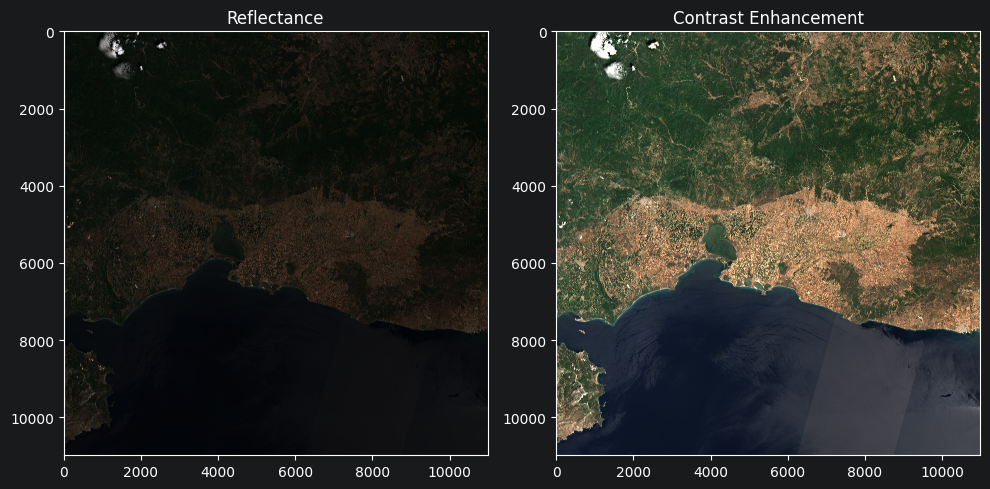

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 10))
ax[0].set_title("Reflectance")
ax[0].imshow(image_refl)

ax[1].set_title("Contrast Enhancement")
ax[1].imshow(image_clipped)

plt.tight_layout()
plt.savefig("plots/refl-contr.png")
plt.show()

Save the RGB raster

In [14]:
image_array.rio.to_raster('plots/image2.tiff')

Insert the items into a Datacube

In [15]:
import odc.stac

test_item1 = item_collection.items[2]
test_item2 = item_collection.items[5]
test_item3 = item_collection.items[8]

thrace_datacube = odc.stac.load(
    [test_item1, test_item2, test_item3],
    bands=['red', 'green', 'blue'],
    groupby="time"
)


Save the datacube in ZARR

In [ ]:
thrace_datacube.to_zarr("data/datacube/thrace.zarr")

# Earth Observation Practice Project — TODO

### Phase 1 — Setup & Data Discovery
- [x] Define AOI with geojson.io
- [x] Search Element84 STAC API for Sentinel-2 L2A scenes (AOI + 10-day window)
- [x] Save search results to JSON

### Phase 2 — Single Tile Exploration
- [x] Extract RGB bands from one tile
- [x] Build 3D multiband array (RGB)
- [x] Convert DN to surface reflectance
- [x] Apply contrast enhancement
- [x] Plot raw and enhanced arrays
- [x] Load RGB bands from collection items into a datacube (xarray)
- [x] Save datacube to Zarr

### Phase 3 — AOI-based Mosaic
- [ ] Reproject tiles to a common CRS if needed (check UTM zones across tiles)
- [ ] Merge/mosaic overlapping tiles covering the AOI
- [ ] Clip the mosaic to the exact AOI geometry (mask with the geojson polygon)
- [ ] Re-plot RGB to confirm the AOI-only crop looks correct
- [ ] Update/re-save the Zarr datacube to store the AOI-cropped version instead of per-tile data

### Phase 4 — Vegetation Index
- [ ] Extract additional bands needed (e.g. NIR for NDVI, or Red-Edge for NDRE)
- [ ] Add NIR (and any other required bands) into the datacube
- [ ] Calculate vegetation index
- [ ] Handle edge cases (cloud/no-data masking)
- [ ] Plot NDVI with an appropriate colormap
- [ ] Sanity-check values against known vegetation/water/urban areas in the AOI

### Phase 5 — Temporal Analysis
- [ ] Query STAC for a wider time window (e.g. full growing season or full year)
- [ ] Filter for cloud cover threshold to drop unusable scenes
- [ ] Batch-download/process the expanded set of scenes into the datacube (time dimension)
- [ ] Compute NDVI for each timestamp
- [ ] Aggregate/resample if needed (e.g. monthly composites, handle gaps)
- [ ] Plot NDVI time series (mean over AOI, or per-pixel animation/facet grid)
- [ ] Compare seasonal patterns — identify peak greenness, senescence, etc.

### Phase 6 — Change Detection (Deforestation / Wildfire / Reforestation)
- [ ] Select before/after time periods relevant to a known event or general monitoring window
- [ ] Calculate NBR (Normalized Burn Ratio) for wildfire/burn scar detection, if SWIR band available
- [ ] Compute NDVI (or NBR) difference between time periods
- [ ] Threshold the difference to flag significant vegetation loss (deforestation/fire) or gain (reforestation)
- [ ] Plot change map highlighting loss/gain areas over the AOI
- [ ] Cross-check flagged areas against known events (fire perimeters, land-use records) if available
- [ ] Summarize findings (area affected, recovery trend over time, etc.)

## Optional Stretch Goals
- [ ] Compare NDVI against another index for cross-validation
- [ ] Export final time series as CSV/plot for a short write-up
